# 06 — Phúc: chọn Teacher trên E2 v1

Đọc từ trên xuống: dữ liệu → mô hình → Group CV → chọn Teacher → fit Train → lỗi → bàn giao → external riêng.

Giữ ba folds cũ, AP làm chính, ngưỡng mặc định. Không dùng Validation/external/Test để chọn. Kết quả tuần 5 được giữ nguyên. Code huấn luyện nằm trực tiếp ở đây.

In [1]:
from pathlib import Path
from time import perf_counter
from io import BytesIO
from datetime import datetime, timezone
from importlib.metadata import version
import sys
import json
import hashlib
import subprocess
import warnings

import joblib
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
from phishguard_vn.brand_features import E2_FEATURES, BRAND_FEATURES, FEATURE_SCHEMA_VERSION, REFERENCE_PATH, load_reference
from phishguard_vn.features import CANDIDATE_FEATURES
from phishguard_vn.prediction import predict_url
from phishguard_vn.splits import audit_domain_overlap

DATA = ROOT / "data/interim"
OUT = ROOT / "reports/tables/week6"
FIGURES = ROOT / "reports/figures/week6"
for folder in [OUT, FIGURES, ROOT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
PROTOCOL = "week6_e2_v1_teacher_groupcv_v1"
FEATURES = list(E2_FEATURES)
CPU_LIMIT = threadpool_limits(limits=1)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print(ROOT, "|", FEATURE_SCHEMA_VERSION, "|", len(FEATURES), "features")

D:\PhishGuardVN | e2-brand-v1 | 20 features


## 1. Đọc dữ liệu và kiểm tra trước khi học

X là 20 đặc trưng E2 v1. y là nhãn; ID/domain/fold chỉ dùng để nối và kiểm tra. Hai URL lỗi vẫn ngoài X như tuần 4. Tập Test được lọc trước khi kiểm tra nhãn hay ghép X.

In [2]:
core = pd.read_csv(DATA / "core_gold_silver.csv", dtype={"id": "string"}, low_memory=False)
core = core.loc[core["split"].isin(["train", "val"])].copy()
X_table = pd.read_csv(DATA / "05_matrix_X_brand_trainval.csv", dtype={"id": "string"})
domains = pd.read_csv(DATA / "03_registrable_domains.csv", dtype={"id": "string"})
domains = domains.loc[domains["id"].isin(core["id"])].copy()
folds = pd.read_csv(DATA / "02_group_folds_train.csv", dtype={"id": "string"})
manifest = json.loads((DATA / "05_matrix_X_brand_trainval.manifest.json").read_text(encoding="utf-8"))
reference = load_reference()

assert FEATURE_SCHEMA_VERSION == manifest["feature_schema_version"] == "e2-brand-v1"
assert reference.is_fully_verified and manifest["brand_reference"]["sha256"] == reference.sha256
assert manifest["partition"] == "trainval" and manifest["test_excluded_from_this_artifact"]
assert manifest["columns"] == list(X_table.columns) == ["id", *FEATURES]
assert manifest["rows_x"] == len(X_table) and manifest["e1_columns_verified_identical_to_e1_matrix"]
assert manifest["input_sha256"] == sha256(DATA / "core_gold_silver.csv")
assert manifest["e1_feature_dictionary_sha256"] == sha256(ROOT / "reports/templates/feature_dictionary.csv")
assert manifest["brand_feature_dictionary_sha256"] == sha256(ROOT / "reports/templates/brand_feature_dictionary.csv")
for name, digest in manifest["splits_sha256"].items():
    assert name in ["url_train.csv", "url_val.csv"]
    assert sha256(ROOT / "data/splits" / name) == digest
for frame in [core, X_table, domains, folds]:
    assert frame["id"].notna().all() and frame["id"].str.strip().ne("").all()
    assert frame["id"].is_unique
assert core["tier"].isin(["gold", "silver"]).all()
assert core["label"].isin(["benign", "phishing"]).all()
assert set(core["id"]) == set(domains["id"])
assert np.isfinite(X_table[FEATURES].to_numpy(float)).all()

metadata = core[["id", "url", "label", "tier", "source", "split"]].merge(
    domains[["id", "registrable_domain"]], on="id", validate="one_to_one")
assert audit_domain_overlap(metadata)["status"] != "overlap_detected"
assert set(X_table["id"]) == set(metadata.loc[metadata["registrable_domain"].notna(), "id"])
e1 = pd.read_csv(DATA / "03_matrix_X_features.csv", dtype={"id": "string"}).set_index("id")
a = X_table.set_index("id")[list(CANDIDATE_FEATURES)].sort_index()
np.testing.assert_allclose(a, e1.loc[a.index, list(CANDIDATE_FEATURES)], rtol=0, atol=1e-9)
eligible = X_table.merge(metadata, on="id", validate="one_to_one")
assert list(folds.columns) == ["id", "fold_id"] and set(folds["fold_id"]) == {0, 1, 2}
assert set(folds["id"]) == set(eligible.loc[eligible["split"].eq("train"), "id"])
train = eligible.loc[eligible["split"].eq("train")].merge(
    folds, on="id", validate="one_to_one").sort_values("id").reset_index(drop=True)
validation = eligible.loc[eligible["split"].eq("val")].sort_values("id").reset_index(drop=True)
for frame in [train, validation]:
    frame["target"] = frame["label"].map({"benign": 0, "phishing": 1})
    assert frame["target"].nunique() == 2
assert train.groupby("registrable_domain")["fold_id"].nunique().eq(1).all()
assert set(train["registrable_domain"]).isdisjoint(validation["registrable_domain"])
print("Train:", len(train), "| Validation:", len(validation), "| Test không vào model")
display(train.groupby(["fold_id", "label"]).size().unstack(fill_value=0))

Train: 13078 | Validation: 1585 | Test không vào model


label,benign,phishing
fold_id,,
0,3668,691
1,3668,691
2,3668,692


## 2. Khai báo mô hình ngay tại đây

Giữ LR thường/balanced, SVM, MLP, HistGB làm các mốc cũ. Thêm Random Forest là ứng viên mới. Mỗi mô hình có tối đa hai cấu hình; khai báo trước khi xem kết quả external. Scaler nằm trong Pipeline; hai mô hình cây không cần scaler.

In [3]:
lr = Pipeline([("scaler", StandardScaler()),
               ("model", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))])
lr_balanced = Pipeline([("scaler", StandardScaler()),
                        ("model", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED))])
svm = Pipeline([("scaler", StandardScaler()),
                ("model", SVC(kernel="rbf", gamma="scale", cache_size=256))])
mlp = Pipeline([("scaler", StandardScaler()),
                ("model", MLPClassifier(alpha=0.001, max_iter=1000, batch_size=256,
                                        early_stopping=False, n_iter_no_change=20, random_state=SEED))])
histgb = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                        l2_regularization=1.0, early_stopping=False, random_state=SEED)
forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, max_features="sqrt",
                                class_weight="balanced", n_jobs=1, random_state=SEED)
models = {"logistic_regression": lr, "logistic_regression_balanced": lr_balanced,
          "svm_rbf": svm, "mlp": mlp, "hist_gradient_boosting": histgb, "random_forest": forest}
param_grids = {"logistic_regression": {}, "logistic_regression_balanced": {},
               "svm_rbf": {"model__C": [0.5, 2.0]},
               "mlp": {"model__hidden_layer_sizes": [(32,), (32, 16)]},
               "hist_gradient_boosting": {"max_leaf_nodes": [7, 15]},
               "random_forest": {"max_depth": [12, None]}}

## 3. Ba hàm ngắn dùng trong các bước dưới

Inner CV chỉ tìm cấu hình trong phần fitting. Outer fold dùng chấm điểm. AP nhận probability hoặc SVM margin; nhãn lấy bằng predict, không chỉnh ngưỡng.

In [4]:
def inner_splits(fitting):
    splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
    splits = list(splitter.split(fitting[FEATURES], fitting["target"], fitting["registrable_domain"]))
    for a, b in splits:
        assert set(fitting.iloc[a]["registrable_domain"]).isdisjoint(fitting.iloc[b]["registrable_domain"])
        assert fitting.iloc[a]["target"].nunique() == fitting.iloc[b]["target"].nunique() == 2
    return splits

def ranking_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    return model.decision_function(X)

def calculate_metrics(y, predicted, score):
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {"pr_auc": average_precision_score(y, score),
            "precision_phishing": precision_score(y, predicted, zero_division=0),
            "recall_phishing": recall_score(y, predicted, zero_division=0),
            "f1_phishing": f1_score(y, predicted, zero_division=0),
            "false_positive_rate": fp / (fp + tn),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

## 4. Chạy ba outer folds — tạo dự đoán OOF

Với mỗi fold: giữ một phần ngoài, tìm cấu hình chỉ trong hai phần còn lại, rồi predict phần giữ ngoài. Mỗi URL Train có đúng một dự đoán OOF cho từng mô hình.

In [5]:
cv_rows, prediction_tables, parameter_rows, partition_tables = [], [], [], []
for fold_id in [0, 1, 2]:
    fitting = train.loc[train["fold_id"].ne(fold_id)]
    held_out = train.loc[train["fold_id"].eq(fold_id)]
    assert set(fitting["id"]).isdisjoint(held_out["id"])
    assert set(fitting["registrable_domain"]).isdisjoint(held_out["registrable_domain"])
    splits = inner_splits(fitting)
    assignments = pd.DataFrame({"id": fitting["id"].to_numpy(), "context": str(fold_id),
                                "role": "fitting", "inner_fold_id": -1})
    for i, (_, score_index) in enumerate(splits):
        assignments.loc[score_index, "inner_fold_id"] = i
    partition_tables.extend([assignments, pd.DataFrame({"id": held_out["id"].to_numpy(),
                              "context": str(fold_id), "role": "held_out", "inner_fold_id": -1})])
    for name, model in models.items():
        start = perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            if param_grids[name]:
                search = GridSearchCV(clone(model), param_grids[name], scoring="average_precision",
                                      cv=splits, n_jobs=1, error_score="raise", refit=True)
                search.fit(fitting[FEATURES], fitting["target"])
                fitted, best_params = search.best_estimator_, search.best_params_
            else:
                fitted = clone(model).fit(fitting[FEATURES], fitting["target"])
                best_params = {}
        predicted = fitted.predict(held_out[FEATURES])
        score = ranking_scores(fitted, held_out[FEATURES])
        assert list(fitted.classes_) == [0, 1] and np.isfinite(score).all()
        cv_rows.append({"model": name, "fold_id": fold_id, "fit_seconds": perf_counter() - start,
                        **calculate_metrics(held_out["target"], predicted, score)})
        prediction_tables.append(pd.DataFrame({"id": held_out["id"].to_numpy(), "model": name,
                "fold_id": fold_id, "true_label": held_out["target"].to_numpy(),
                "predicted_label": predicted, "score": score,
                "score_kind": "decision_function" if name == "svm_rbf" else "probability"}))
        parameter_rows.append({"model": name, "context": str(fold_id),
                               "parameters": json.dumps(best_params, sort_keys=True)})
        print(name, "fold", fold_id, "AP =", round(cv_rows[-1]["pr_auc"], 4), flush=True)
cv_metrics = pd.DataFrame(cv_rows)
oof = pd.concat(prediction_tables, ignore_index=True)
partitions = pd.concat(partition_tables, ignore_index=True)
assert not oof.duplicated(["model", "id"]).any()
assert oof.groupby("model").size().eq(len(train)).all()
assert set(oof["id"]) == set(train["id"])

logistic_regression fold 0 AP = 0.6442


logistic_regression_balanced fold 0 AP = 0.6274


svm_rbf fold 0 AP = 0.6955


mlp fold 0 AP = 0.7272


hist_gradient_boosting fold 0 AP = 0.7252


random_forest fold 0 AP = 0.712


... (8 outputs left out)

svm_rbf fold 2 AP = 0.6565


mlp fold 2 AP = 0.7433


hist_gradient_boosting fold 2 AP = 0.7052


random_forest fold 2 AP = 0.7161


## 5. Chốt Teacher từ Train Group CV

Xếp mean AP giảm dần; nếu hòa, F1 cao hơn rồi FPR thấp hơn và tên. Chưa xem Validation hoặc external ở bước này. Mean/std ba folds chỉ là thống kê mô tả, không phải khoảng tin cậy.

In [6]:
metric_names = ["pr_auc", "recall_phishing", "false_positive_rate", "f1_phishing", "precision_phishing"]
comparison = cv_metrics.groupby("model")[metric_names].agg(["mean", "std"])
comparison.columns = [f"{m}_{s}" for m, s in comparison.columns]
comparison = comparison.reset_index().sort_values(
    ["pr_auc_mean", "f1_phishing_mean", "false_positive_rate_mean", "model"],
    ascending=[False, False, True, True]).reset_index(drop=True)
teacher_name = str(comparison.iloc[0]["model"])
print("Teacher đã chọn trước Validation/external:", teacher_name)
display(comparison)

Teacher đã chọn trước Validation/external: mlp


,model,pr_auc_mean,pr_auc_std,recall_phishing_mean,recall_phishing_std,false_positive_rate_mean,false_positive_rate_std,f1_phishing_mean,f1_phishing_std,precision_phishing_mean,precision_phishing_std
0,mlp,0.726370,0.017394,0.500968,0.010135,0.018811,0.002885,0.625909,0.010894,0.834180,0.021517
1,hist_gradient_boosting,0.723026,0.016832,0.506768,0.035250,0.019993,0.001502,0.627932,0.027031,0.826944,0.001709
2,random_forest,0.717593,0.006483,0.730941,0.029217,0.170665,0.033072,0.555673,0.024138,0.450131,0.042392
3,svm_rbf,0.654746,0.041631,0.462872,0.006084,0.015631,0.005414,0.598973,0.009076,0.849721,0.042595
4,logistic_regression,0.643216,0.004122,0.368385,0.027165,0.022810,0.003820,0.494244,0.022117,0.753806,0.021223
5,logistic_regression_balanced,0.632661,0.010118,0.743479,0.022669,0.192385,0.033895,0.539026,0.022334,0.423995,0.033582


## 6. Fit toàn Train, kiểm tra Validation bổ sung

Model cuối chỉ học Train. Inner Group CV trên toàn Train chọn cấu hình của mỗi họ; không dùng Validation để chọn lại Teacher. Cảnh báo không hội tụ sẽ dừng thay vì lưu model chưa hội tụ.

In [7]:
final_models, validation_rows, validation_tables = {}, [], []
splits = inner_splits(train)
assignments = pd.DataFrame({"id": train["id"].to_numpy(), "context": "full_train",
                           "role": "fitting", "inner_fold_id": -1})
for i, (_, score_index) in enumerate(splits):
    assignments.loc[score_index, "inner_fold_id"] = i
partitions = pd.concat([partitions, assignments], ignore_index=True)
for name, model in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        if param_grids[name]:
            search = GridSearchCV(clone(model), param_grids[name], scoring="average_precision",
                                  cv=splits, n_jobs=1, error_score="raise", refit=True)
            search.fit(train[FEATURES], train["target"])
            fitted, best_params = search.best_estimator_, search.best_params_
        else:
            fitted = clone(model).fit(train[FEATURES], train["target"])
            best_params = {}
    final_models[name] = fitted
    parameter_rows.append({"model": name, "context": "full_train",
                           "parameters": json.dumps(best_params, sort_keys=True)})
    predicted = fitted.predict(validation[FEATURES])
    score = ranking_scores(fitted, validation[FEATURES])
    validation_rows.append({"model": name, **calculate_metrics(validation["target"], predicted, score)})
    validation_tables.append(pd.DataFrame({"id": validation["id"].to_numpy(), "model": name,
        "true_label": validation["target"].to_numpy(), "predicted_label": predicted, "score": score}))
validation_metrics = pd.DataFrame(validation_rows)
validation_predictions = pd.concat(validation_tables, ignore_index=True)
display(validation_metrics)

,model,pr_auc,precision_phishing,recall_phishing,f1_phishing,false_positive_rate,tn,fp,fn,tp
0,logistic_regression,0.348878,0.288889,0.541667,0.376812,0.020500,1529,32,11,13
1,logistic_regression_balanced,0.310228,0.054502,0.958333,0.103139,0.255605,1162,399,1,23
2,svm_rbf,0.244777,0.352941,0.500000,0.413793,0.014094,1539,22,12,12
3,mlp,0.393050,0.250000,0.500000,0.333333,0.023062,1525,36,12,12
4,hist_gradient_boosting,0.447271,0.378378,0.583333,0.459016,0.014734,1538,23,10,14
5,random_forest,0.385363,0.050218,0.958333,0.095436,0.278668,1126,435,1,23


## 7. Đọc ít nhất 10 lỗi OOF của Teacher

Chọn cố định hai lỗi mỗi nhóm fold × FP/FN nếu có, không lấy riêng fold dễ giải thích. Quan sát là dữ kiện; giả thuyết chưa được xác minh nguyên nhân hay nhãn website.

In [8]:
teacher_oof = oof.loc[oof["model"].eq(teacher_name)].merge(
    train[["id", "url", "source", "registrable_domain", *FEATURES]], on="id", validate="one_to_one")
mistakes = teacher_oof.loc[teacher_oof["true_label"].ne(teacher_oof["predicted_label"])].copy()
mistakes["error"] = np.where(mistakes["true_label"].eq(0), "FP", "FN")
error_examples = mistakes.sort_values("id").groupby(["fold_id", "error"], sort=True).head(2).copy()
assert len(error_examples) >= 10 and error_examples["id"].is_unique
error_notes = []
for row in error_examples.itertuples():
    fitting = train.loc[train["fold_id"].ne(row.fold_id)]
    values = np.array([getattr(row, c) for c in FEATURES], dtype=float)
    same_vector = np.isclose(fitting[FEATURES].to_numpy(float), values, rtol=0, atol=1e-12).all(axis=1)
    opposite = int((same_vector & fitting["target"].ne(row.true_label).to_numpy()).sum())
    active = [c for c in BRAND_FEATURES if getattr(row, c) != 0]
    observation = (f"{row.error}, fold {row.fold_id}, score={row.score:.4f}; "
                   f"url_len={row.url_len:g}, dom_len={row.dom_len:g}, entropy={row.entropy:.3f}; "
                   f"brand khác 0: {', '.join(active) or 'không có'}; "
                   f"{opposite} mẫu nhãn đối lập cùng vector E2 trong fitting fold.")
    if opposite:
        hypothesis = "Biểu diễn E2 có thể chưa tách được các URL khác nhãn nhưng có cùng vector."
        next_check = f"Đối chiếu {opposite} fitting rows trùng vector với ID {row.id}; xem nhãn/nguồn, không sửa nhãn theo dự đoán."
    elif row.error == "FP" and row.brand_domain_mismatch:
        hypothesis = "Brand mismatch có thể là false match hoặc reference chưa bao phủ; chưa chứng minh đây là nguyên nhân dự đoán."
        next_check = f"Dùng explain_brand_matches cho hostname {row.registrable_domain}; đối chiếu alias/domain trong reference v1."
    elif row.error == "FN" and not active:
        hypothesis = "Không có tín hiệu brand ở mẫu này; các đặc trưng cấu trúc có thể giống benign trong fitting."
        next_check = f"So URL {row.id} với fitting cùng độ dài/domain length; kiểm tra giới hạn reference mà không chọn rule theo holdout."
    else:
        hypothesis = "Tín hiệu cấu trúc/brand có thể chồng lấn giữa hai lớp; score không phải bằng chứng nhãn nguồn sai."
        next_check = f"Đối chiếu feature của {row.id} trong chính fitting fold và kiểm tra matching; không tune theo lỗi holdout này."
    error_notes.append({"observation": observation, "hypothesis": hypothesis, "next_check": next_check,
                        "opposite_label_same_vector_in_fitting": opposite,
                        "analysis_method": "offline_feature_evidence_not_human_label_verification"})
error_examples = pd.concat([error_examples.reset_index(drop=True), pd.DataFrame(error_notes)], axis=1)
error_examples["url"] = error_examples["url"].str.replace(".", "[.]", regex=False)
display(error_examples[["id", "fold_id", "error", "url", "score", "observation", "hypothesis", "next_check"]])

,id,fold_id,error,url,score,observation,hypothesis,next_check
0,0017a2da-35d5-588f-8062-349ea6be2ec7,0,FN,kokatrade[.]com,0.134742,"FN, fold 0, score=0.1347; url_len=13, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 67 fitting rows trùng vector với ID ...
1,0041597b-64fe-5b47-88fe-40388a88a466,0,FN,mrhmfund[.]com,0.138007,"FN, fold 0, score=0.1380; url_len=12, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 25 fitting rows trùng vector với ID ...
2,00c6d664-b0bd-57ac-8c17-c030f6008ff7,2,FN,vn-inc[.]info,0.332863,"FN, fold 2, score=0.3329; url_len=11, dom_len=...",Không có tín hiệu brand ở mẫu này; các đặc trư...,So URL 00c6d664-b0bd-57ac-8c17-c030f6008ff7 vớ...
3,00dd46cf-3bb2-5276-b4dc-497dd8e8f9d3,1,FN,b1dv[.]xyz,0.193966,"FN, fold 1, score=0.1940; url_len=8, dom_len=8...",Tín hiệu cấu trúc/brand có thể chồng lấn giữa ...,Đối chiếu feature của 00dd46cf-3bb2-5276-b4dc-...
4,011bd9f8-1450-5346-a9b6-638e651b6fd3,0,FP,pos365[.]vn,0.602156,"FP, fold 0, score=0.6022; url_len=9, dom_len=9...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 5 fitting rows trùng vector với ID 0...
5,018a7b82-c2cd-598a-8cfe-df160fa3f408,1,FN,masothue[.]biz,0.126073,"FN, fold 1, score=0.1261; url_len=12, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 18 fitting rows trùng vector với ID ...
6,01e34709-db9f-52dd-b60c-a064312ff7f4,2,FN,pinuian[.]top,0.164636,"FN, fold 2, score=0.1646; url_len=11, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 39 fitting rows trùng vector với ID ...
7,0275e074-bc91-5f20-bb5f-f2f453c257dc,2,FP,11478[.]com,0.625704,"FP, fold 2, score=0.6257; url_len=9, dom_len=9...",Tín hiệu cấu trúc/brand có thể chồng lấn giữa ...,Đối chiếu feature của 0275e074-bc91-5f20-bb5f-...
8,043a298e-278f-5149-8d2a-41d0f005aa2b,1,FP,vnpayment[.]vn,0.983658,"FP, fold 1, score=0.9837; url_len=12, dom_len=...",Brand mismatch có thể là false match hoặc refe...,Dùng explain_brand_matches cho hostname vnpaym...
9,04dd5f6a-beae-54a3-a594-2f4af4dc75d0,0,FP,24hstore[.]vn,0.642868,"FP, fold 0, score=0.6429; url_len=11, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 3 fitting rows trùng vector với ID 0...


## 8. So sánh tốc độ và kích thước

Đo mọi model trên cùng 128 vector Train, một CPU thread, 5 warm-up + 30 lần đo. Đây là thời gian PC predict + score trên X có sẵn, chưa gồm parser/UI/network; không gọi là benchmark điện thoại.

,model,pr_auc_mean,pr_auc_std,recall_phishing_mean,recall_phishing_std,false_positive_rate_mean,false_positive_rate_std,f1_phishing_mean,f1_phishing_std,precision_phishing_mean,precision_phishing_std,pipeline_bytes,batch_size,latency_p50_ms,latency_p95_ms,scope
0,mlp,0.726370,0.017394,0.500968,0.010135,0.018811,0.002885,0.625909,0.010894,0.834180,0.021517,36705,128,1.42040,1.860110,"PC predict+score, precomputed X, 1 thread, war..."
1,hist_gradient_boosting,0.723026,0.016832,0.506768,0.035250,0.019993,0.001502,0.627932,0.027031,0.826944,0.001709,146992,128,4.32450,5.251810,"PC predict+score, precomputed X, 1 thread, war..."
2,random_forest,0.717593,0.006483,0.730941,0.029217,0.170665,0.033072,0.555673,0.024138,0.450131,0.042392,5401865,128,29.34700,35.211095,"PC predict+score, precomputed X, 1 thread, war..."
3,svm_rbf,0.654746,0.041631,0.462872,0.006084,0.015631,0.005414,0.598973,0.009076,0.849721,0.042595,543885,128,43.63330,54.936655,"PC predict+score, precomputed X, 1 thread, war..."
4,logistic_regression,0.643216,0.004122,0.368385,0.027165,0.022810,0.003820,0.494244,0.022117,0.753806,0.021223,2497,128,1.60170,2.552810,"PC predict+score, precomputed X, 1 thread, war..."
5,logistic_regression_balanced,0.632661,0.010118,0.743479,0.022669,0.192385,0.033895,0.539026,0.022334,0.423995,0.033582,2513,128,1.32615,1.605975,"PC predict+score, precomputed X, 1 thread, war..."


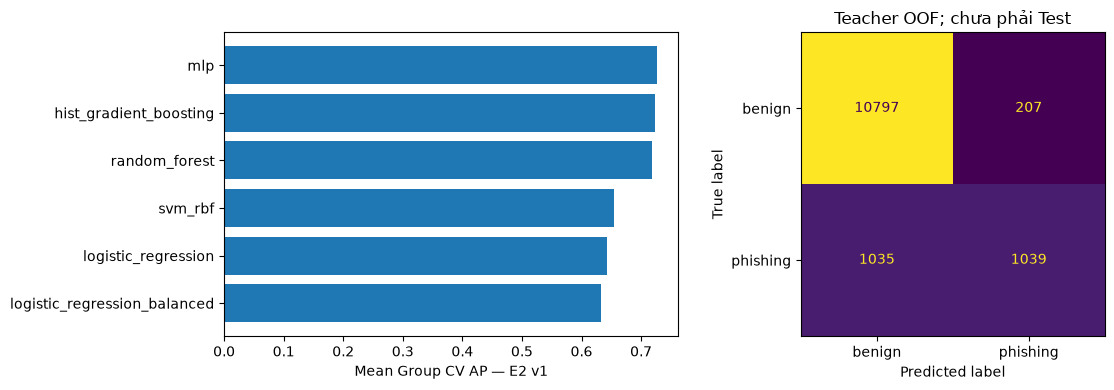

In [9]:
resource_rows = []
for name, fitted in final_models.items():
    stream = BytesIO()
    joblib.dump(fitted, stream)
    durations = []
    sample = train[FEATURES].iloc[:128]
    for repeat in range(35):
        start = perf_counter()
        fitted.predict(sample)
        ranking_scores(fitted, sample)
        if repeat >= 5:
            durations.append((perf_counter() - start) * 1000)
    resource_rows.append({"model": name, "pipeline_bytes": stream.tell(), "batch_size": len(sample),
                         "latency_p50_ms": float(np.median(durations)),
                         "latency_p95_ms": float(np.quantile(durations, 0.95)),
                         "scope": "PC predict+score, precomputed X, 1 thread, warmup=5, repeats=30"})
resources = pd.DataFrame(resource_rows)
comparison = comparison.merge(resources, on="model", validate="one_to_one")
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(comparison["model"][::-1], comparison["pr_auc_mean"][::-1])
axes[0].set_xlabel("Mean Group CV AP — E2 v1")
teacher_rows = oof.loc[oof["model"].eq(teacher_name)]
ConfusionMatrixDisplay.from_predictions(teacher_rows["true_label"], teacher_rows["predicted_label"],
                                       labels=[0, 1], display_labels=["benign", "phishing"], ax=axes[1], colorbar=False)
axes[1].set_title("Teacher OOF; chưa phải Test")
fig.tight_layout()
fig.savefig(FIGURES / "teacher_comparison.png", dpi=150)
plt.show()

## 9. Lưu Teacher, kết quả và thông tin bàn giao

Bundle chỉ chứa Teacher được chọn, reference snapshot và đúng thứ tự 20 features. File lock nối model với quyết định chọn bằng Train CV. Không sửa/tái sử dụng kết quả v0 thành v1.

In [10]:
extractor_hashes = {name: hashlib.sha256((ROOT / "src/phishguard_vn" / name).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                    for name in ["features.py", "url_parser.py", "brand_features.py"]}
score_kind = "decision_function" if teacher_name == "svm_rbf" else "probability"
bundle = {"models": {teacher_name: final_models[teacher_name]}, "selected_model": teacher_name,
          "feature_names": FEATURES, "feature_set": FEATURE_SCHEMA_VERSION,
          "score_kinds": {teacher_name: score_kind}, "protocol": PROTOCOL,
          "decision_rule": "estimator.predict", "brand_reference": reference,
          "extractor_source_sha256": extractor_hashes}
model_path = ROOT / "models/week6_teacher_v1.joblib"
joblib.dump(bundle, model_path)
compression = {"method": "gzip", "mtime": 0}
for name, frame in {"cv_metrics": cv_metrics, "comparison": comparison, "validation": validation_metrics,
                    "parameters": pd.DataFrame(parameter_rows), "errors": error_examples,
                    "resources": resources}.items():
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8", lineterminator="\n")
for name, frame in {"oof_predictions": oof, "validation_predictions": validation_predictions,
                    "training_partitions": partitions}.items():
    frame.to_csv(OUT / f"{name}.csv.gz", index=False, compression=compression, lineterminator="\n")
input_paths = [DATA / n for n in ["core_gold_silver.csv", "03_matrix_X_features.csv",
               "03_registrable_domains.csv", "02_group_folds_train.csv",
               "05_matrix_X_brand_trainval.csv", "05_matrix_X_brand_trainval.manifest.json"]]
notebook = nbformat.read(ROOT / "notebooks/06_teacher_v1.ipynb", as_version=4)
training_code = "\n".join(c.source for c in notebook.cells if c.cell_type == "code")
selection = {"protocol": PROTOCOL, "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "created_utc": datetime.now(timezone.utc).isoformat(), "teacher_finalized": True,
    "selected_by": "core_train_group_cv", "external_used_for_selection": False,
    "primary_metric": "mean_outer_average_precision", "selection_rule": "AP desc; F1 desc; FPR asc; model name asc",
    "selected_candidate": f"E2__{teacher_name}", "teacher_candidates": [f"E2__{teacher_name}"],
    "train_rows": len(train), "validation_rows": len(validation), "test_evaluated": False,
    "seed": SEED, "outer_folds": 3, "inner_folds": 2, "features": FEATURES,
    "reference": reference.summary(), "extractor_source_lf_sha256": extractor_hashes,
    "notebook_code_sha256": hashlib.sha256(training_code.encode("utf-8")).hexdigest(),
    "runtime_git_revision": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "runtime_git_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip()),
    "versions": {n: version(n) for n in ["scikit-learn", "numpy", "pandas", "joblib", "tldextract", "idna"]},
    "input_sha256": {p.relative_to(ROOT).as_posix(): sha256(p) for p in input_paths},
    "parameters": parameter_rows, "bundle_sha256": sha256(model_path)}
selection_path = OUT / "teacher_selection.json"
selection_path.write_text(json.dumps(selection, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
lock = {"teacher_finalized": True, "selected_by": "core_train_group_cv", "external_used_for_selection": False,
    "model_name": teacher_name, "feature_set": FEATURE_SCHEMA_VERSION, "score_kind": score_kind,
    "decision_rule": "estimator.predict", "threshold": 0 if score_kind == "decision_function" else 0.5,
    "operating_point_scope": "fixed_core_protocol",
    "bundle": {"path": model_path.relative_to(ROOT).as_posix(), "sha256": sha256(model_path)},
    "selection_record": {"path": selection_path.relative_to(ROOT).as_posix(), "sha256": sha256(selection_path)}}
(ROOT / "configs/week6_teacher_lock.json").write_text(
    json.dumps(lock, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
print("Đã lưu:", model_path, "|", teacher_name, "|", model_path.stat().st_size, "bytes")

Đã lưu: D:\PhishGuardVN\models\week6_teacher_v1.joblib | mlp | 44135 bytes


## 10. Load model và thử năm URL, không truy cập website

Các URL là ví dụ gọi hàm, không phải ground truth mới. Score chưa hiệu chuẩn thành tỷ lệ bị lừa.

In [11]:
loaded = joblib.load(model_path)
demo_urls = ["https://www.vietcombank.com.vn", "https://vietcombank-login.example.com/xacminh",
             "https://example.com/login?account=123", "https://xn--bcher-kva.de", "https://www.hcmus.edu.vn"]
demo_results = []
for url in demo_urls:
    result = predict_url(url, loaded)
    demo_results.append({"url": url, **result})
    print(url, "=>", result["label"], round(result["score"], 4))
pd.DataFrame(demo_results).to_csv(OUT / "demo_predictions.csv", index=False, encoding="utf-8", lineterminator="\n")

https://www.vietcombank.com.vn => benign 0.0
https://vietcombank-login.example.com/xacminh => phishing 1.0
https://example.com/login?account=123 => phishing 0.9985
https://xn--bcher-kva.de => benign 0.0
https://www.hcmus.edu.vn => benign 0.0008


## 11. External host-only — phép thử tham khảo sau khi khóa Teacher

Dùng audit đã có, không thu thập thêm. 167 candidate giữ nguyên; chỉ subset có review phù hợp được chấm. Hai lớp dùng cùng hostname, không thêm scheme/path giả. Hai-class là exploratory với rất ít benign; báo recall phishing theo nguồn riêng. Không đưa bất kỳ kết quả nào ở đây ngược về lựa chọn model.

In [12]:
from phishguard_vn.external_pilot import load_locked_teacher, evaluate_verified

external_manifest = json.loads((ROOT / "reports/tables/external_pilot/manifest.json").read_text(encoding="utf-8"))
for path, digest in {**external_manifest["inputs_sha256"], **external_manifest["outputs_sha256"]}.items():
    assert sha256(ROOT / path) == digest, f"Audit external đã đổi: {path}"
ledger = pd.read_csv(ROOT / "data/external/derived/k53_candidates.csv", keep_default_na=False, encoding="utf-8")
locked_predictor = load_locked_teacher(ROOT, lock)
recall_pilot, verified_predictions = evaluate_verified(ledger, locked_predictor, representation="host_only")
two_class, _ = evaluate_verified(ledger, locked_predictor, representation="host_only", two_class=True)
all_results = []
for row in ledger.itertuples():
    result = locked_predictor(row.model_input_host)
    all_results.append({"id": row.id, "model_input_host": row.model_input_host,
        "candidate_label": row.label, "review_status": row.review_status, "label_scope": row.label_scope,
        "prediction": result["label"], "score": result["score"], "score_kind": result["score_kind"]})
external_results = {"teacher_locked_before_external": True, "official": False,
    "recall_pilot": recall_pilot, "two_class_exploratory": two_class,
    "raw_candidates": len(ledger), "pending_not_scored": int(ledger["review_status"].eq("pending").sum()),
    "selection_record_sha256": sha256(selection_path),
    "limitations": ["Host-only, historical evidence; không xác nhận tình trạng website hiện tại.",
                    "Chỉ 7 benign được review; FPR/precision hai-class chỉ tham khảo, còn source bias.",
                    "Không dùng pending làm ground truth; không chọn lại model/ngưỡng theo external."]}
(OUT / "external_results.json").write_text(
    json.dumps(external_results, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
pd.DataFrame(all_results).to_csv(OUT / "external_all_predictions.csv", index=False, encoding="utf-8", lineterminator="\n")
verified_predictions.to_csv(OUT / "external_verified_predictions.csv", index=False, encoding="utf-8", lineterminator="\n")
display(pd.DataFrame(recall_pilot["by_source"]))
print(json.dumps(external_results, ensure_ascii=False, indent=2))

,source,n,positive_support,negative_support,tp,fn,recall_phishing,precision,f1,accuracy,fpr
0,ACB official list of fake websites,37,37,0,35,2,0.945946,None,None,None,None
1,Agribank official warning of spoofed domains,2,2,0,1,1,0.500000,None,None,None,None
2,BIDV official consumer fraud warning,4,4,0,4,0,1.000000,None,None,None,None
3,Bac Ninh government local public-service scam ...,1,1,0,1,0,1.000000,None,None,None,None
4,NCSC warning republished by Dak Lak government,36,36,0,14,22,0.388889,None,None,None,None
5,NCSC weekly scam warnings on Ministry portal,1,1,0,0,1,0.000000,None,None,None,None
6,Quang Ngai police publication of NCSC warning,10,10,0,6,4,0.600000,None,None,None,None
7,VNCERT/CC warning on Ministry portal,1,1,0,1,0,1.000000,None,None,None,None


{
  "teacher_locked_before_external": true,
  "official": false,
  "recall_pilot": {
    "status": "PHISHING_RECALL_PILOT",
    "official": false,
    "representation": "host_only",
    "metrics": {
      "n": 92,
      "positive_support": 92,
      "negative_support": 0,
      "tp": 62,
      "fn": 30,
      "recall_phishing": 0.6739130434782609,
      "precision": null,
      "f1": null,
      "accuracy": null,
      "fpr": null
    },
    "n_candidates": 167,
    "n_evaluated": 92,
    "by_source": [
      {
        "source": "ACB official list of fake websites",
        "n": 37,
        "positive_support": 37,
        "negative_support": 0,
        "tp": 35,
        "fn": 2,
        "recall_phishing": 0.9459459459459459,
        "precision": null,
        "f1": null,
        "accuracy": null,
        "fpr": null
      },
      {
        "source": "Agribank official warning of spoofed domains",
        "n": 2,
        "positive_support": 2,
        "negative_support": 0,
        "tp

## Đọc và phát triển tiếp

Bắt đầu ở bước 2 để thấy model được tạo; bước 4 là fit/predict OOF; bước 5 chọn Teacher; bước 6 fit bản bàn giao; bước 9 lưu model và lock. External không thay đổi quyết định. Chưa tạo soft targets hay làm KD; Teacher fit toàn Train không được dùng để tạo target rồi chấm lại OOF trên cùng Train.